In [118]:
import matplotlib.pyplot as plt
import platform
# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
"Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

In [119]:
import pandas as pd

df=pd.read_csv("sales_data.csv")
df.shape

(1030, 14)

In [120]:
df.head()

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
0,2023-01-01,2023-01-04,2023-01-03,부산,전자제품,2772,61,34977.69,327,67.0,M,1.0,배송중,2133639.09
1,2023-01-02,2023-01-06,2023-01-04,부산,식품,3780,64,312589.27,318,34.0,M,4.0,배송완료,20005713.28
2,2023-01-03,2023-01-04,2023-01-05,부산,의류,8423,5,111813.88,297,50.0,F,4.0,배송완료,559069.40
3,2023-01-04,2023-01-07,2023-01-10,대구,식품,3871,53,297971.54,479,61.0,M,5.0,배송완료,15792491.62
4,2023-01-05,2023-01-08,2023-01-10,서울,식품,1660,55,65058.60,499,60.0,F,2.0,배송중,3578223.00


In [121]:
df.iloc[0]

order_date         2023-01-01
shipping_date      2023-01-04
delivery_date      2023-01-03
region                     부산
category                 전자제품
product_id               2772
quantity                   61
unit_price           34977.69
customer_id               327
customer_age             67.0
customer_gender             M
satisfaction              1.0
status                    배송중
total_sales        2133639.09
Name: 0, dtype: object

In [122]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_date       1030 non-null   str    
 1   shipping_date    1030 non-null   str    
 2   delivery_date    1025 non-null   str    
 3   region           1030 non-null   str    
 4   category         1030 non-null   str    
 5   product_id       1030 non-null   int64  
 6   quantity         1030 non-null   int64  
 7   unit_price       1030 non-null   float64
 8   customer_id      1030 non-null   int64  
 9   customer_age     979 non-null    float64
 10  customer_gender  1030 non-null   str    
 11  satisfaction     1000 non-null   float64
 12  status           1030 non-null   str    
 13  total_sales      1030 non-null   float64
dtypes: float64(4), int64(3), str(7)
memory usage: 112.8 KB


In [123]:
df.describe()

,product_id,quantity,unit_price,customer_id,customer_age,satisfaction,total_sales
count,1030.000000,1030.000000,1030.000000,1030.000000,979.000000,1000.000000,1.030000e+03
mean,5365.692233,65.134951,248893.777214,240.780583,44.858018,2.956000,1.235946e+07
std,2557.264515,113.597931,139497.370968,147.105954,14.253807,1.458146,1.065892e+07
min,1002.000000,1.000000,10455.410000,1.000000,20.000000,1.000000,2.376040e+04
25%,3292.500000,25.000000,129378.125000,107.000000,32.000000,2.000000,3.456833e+06
50%,5191.500000,50.000000,247732.410000,234.500000,45.000000,3.000000,9.425458e+06
75%,7581.250000,75.000000,369780.650000,368.750000,57.000000,4.000000,1.920825e+07
max,9996.000000,990.000000,498783.880000,499.000000,69.000000,5.000000,4.688031e+07


In [124]:
df.isnull().sum()

order_date          0
shipping_date       0
delivery_date       5
region              0
category            0
product_id          0
quantity            0
unit_price          0
customer_id         0
customer_age       51
customer_gender     0
satisfaction       30
status              0
total_sales         0
dtype: int64

In [125]:
print(df.duplicated().sum())

26


In [126]:
calc=df["quantity"] * df["unit_price"]
diff=(df["total_sales"]-calc).abs()
print((diff>1).sum())

22


In [127]:
cols = ["quantity", "unit_price", "total_sales"]
df.loc[diff > 1, cols].head(3)

,quantity,unit_price,total_sales
31,528,235225.85,22346455.75
188,943,303984.25,19151007.75
273,656,242263.07,18654256.39


In [128]:
dates = ["order_date", "shipping_date",
"delivery_date"]
for col in dates:
  df[col] = pd.to_datetime(df[col])
df[dates].agg(["min", "max"])

,order_date,shipping_date,delivery_date
min,2023-01-01,2023-01-04,2023-01-03
max,2025-09-26,2025-09-29,2026-09-14


In [129]:
today = pd.Timestamp.today()
late = df["shipping_date"] < df["order_date"]
rev = df["delivery_date"] < df["shipping_date"]
print("미래날짜 :", (df["order_date"] > today).sum())
print("배송일 < 주문일 :", late.sum())
print("도착일 < 배송일 :", rev.sum())

미래날짜 : 0
배송일 < 주문일 : 0
도착일 < 배송일 : 149


In [130]:
import matplotlib.pyplot as plt
import platform
# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
"Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

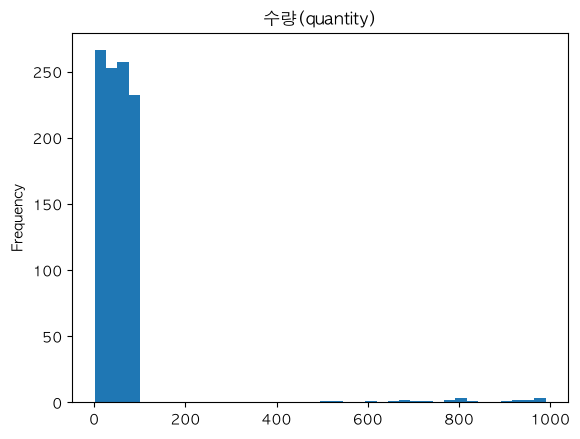

In [131]:
df["quantity"].plot.hist(bins=40, title="수량(quantity)")
plt.show()

In [132]:
Q1 = df["quantity"].quantile(0.25)
Q3 = df["quantity"].quantile(0.75)
IQR = Q3 - Q1
print("Q1 =", Q1, " Q3 =", Q3, " IQR =", IQR)
print("수염 끝(상한) =", Q3 + 1.5 * IQR)

Q1 = 25.0  Q3 = 75.0  IQR = 50.0
수염 끝(상한) = 150.0


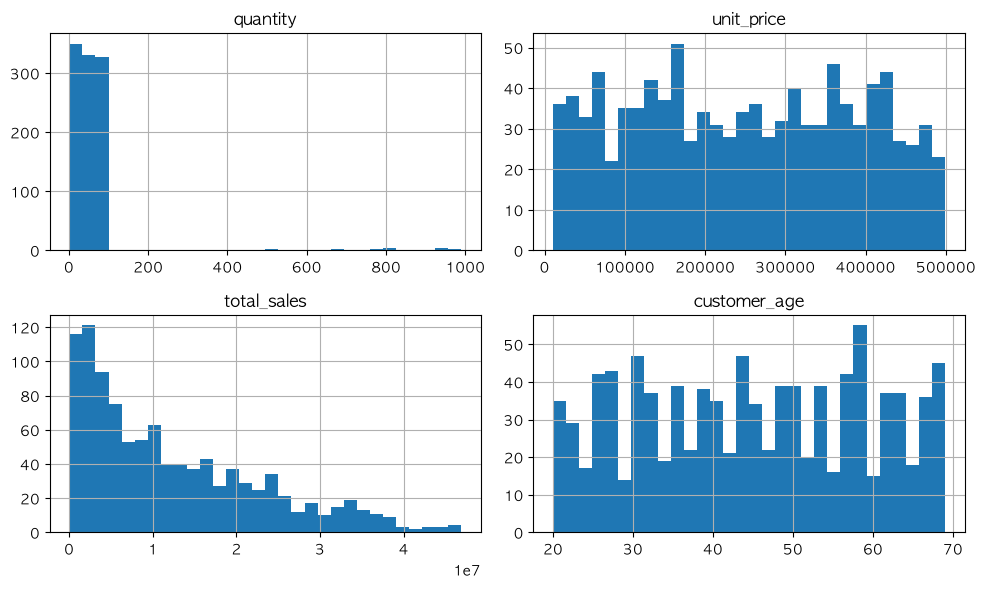

In [133]:
cols = ["quantity", "unit_price",
"total_sales", "customer_age"]
df[cols].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

In [134]:
dropped = df.dropna(subset=["customer_age"])
print(len(df), "->", len(dropped))

1030 -> 979


In [135]:
age_mean=df["customer_age"].fillna(df["customer_age"].mean())
print("평균 :", round(age_mean.mean(), 3))
print("중앙값:", round(age_mean.median(), 3))
print("최빈값:", round(age_mean.mode()[0], 3))

평균 : 44.858
중앙값: 44.858
최빈값: 44.858


In [136]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


In [137]:
by_iqr = df["quantity"] > Q3 + 1.5 * IQR # 통계 규칙 : 26쪽 상한 150 밖
by_rule = df["quantity"] > 100 # 업무 규칙 : 한 주문 100개 넘지 않는다
print("IQR 규칙 :", by_iqr.sum(), " 업무 규칙 :", by_rule.sum(), " 둘이 같은 줄인가 :", (by_iqr == by_rule).all())

IQR 규칙 : 22  업무 규칙 : 22  둘이 같은 줄인가 : True


In [138]:
bad = by_rule
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print("22건 중 금액이 안 맞는 줄 :", (diff[bad] > 1).sum())
ratio = df["total_sales"] / df["unit_price"]
ratio[bad].round(2).head(6)

22건 중 금액이 안 맞는 줄 : 22


31     95.0
188    63.0
273    77.0
316    52.0
334    18.0
361    82.0
dtype: float64

In [139]:
df.loc[bad, "quantity"] = ratio[bad].round().astype(int)
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print("수량 최대 :", df["quantity"].max(), " 불일치 :", (diff > 1).sum())

수량 최대 : 99  불일치 : 0


In [140]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df["date_error"].value_counts()

date_error
False    857
True     147
Name: count, dtype: int64

In [141]:
df.to_csv("sales_clean.csv", index=False)
df.shape

(1004, 15)

In [142]:
df[["quantity", "unit_price", "total_sales", "customer_age"]].agg(["mean", "median", "skew"]).round(2)

,quantity,unit_price,total_sales,customer_age
mean,49.41,250146.14,12413727.16,44.90
median,48.00,249449.48,9425457.90,45.00
skew,0.04,0.00,0.94,-0.02


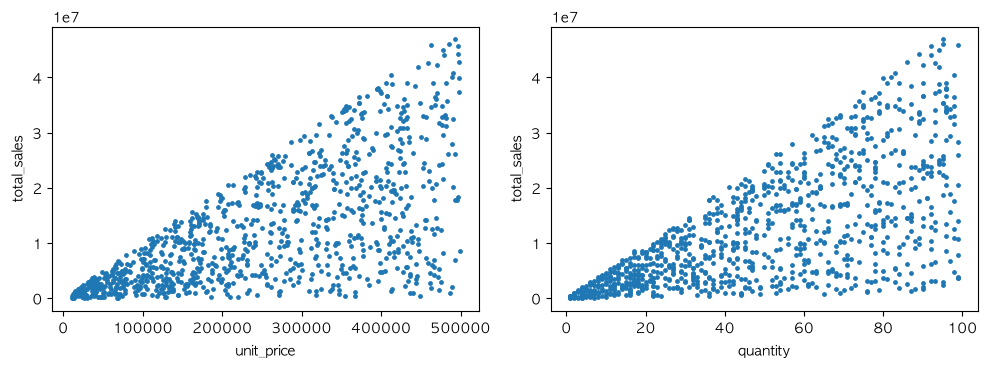

In [143]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
df.plot.scatter(x="unit_price", y="total_sales", s=6, ax=ax[0])
df.plot.scatter(x="quantity", y="total_sales", s=6, ax=ax[1])
plt.tight_layout()
plt.show()

In [144]:
num = ["quantity", "unit_price", "total_sales",
"customer_age", "satisfaction"]
df[num].corr().round(2)

,quantity,unit_price,total_sales,customer_age,satisfaction
quantity,1.00,0.01,0.67,0.03,0.02
unit_price,0.01,1.00,0.65,-0.07,0.06
total_sales,0.67,0.65,1.00,-0.05,0.06
customer_age,0.03,-0.07,-0.05,1.00,-0.05
satisfaction,0.02,0.06,0.06,-0.05,1.00


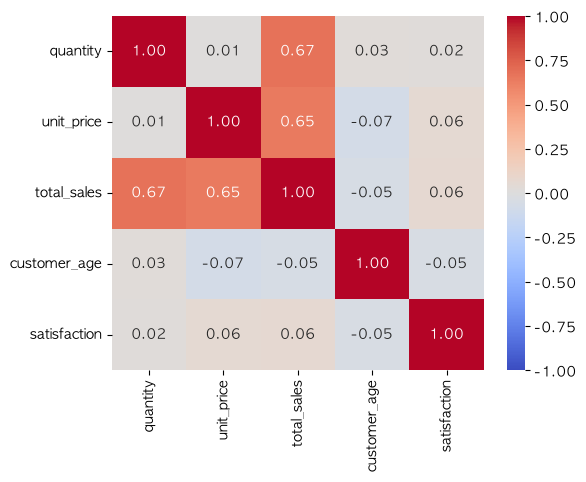

In [145]:
import seaborn as sns
plt.figure(figsize=(6, 4.6))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f",
cmap="coolwarm", center=0,
vmin=-1, vmax=1)
plt.show()

In [146]:
by_cat = df.groupby("category")["total_sales"].sum()
(by_cat / 1e8).round(1) # 억 원 단위

category
가구      28.4
도서      24.5
식품      25.1
의류      21.8
전자제품    24.7
Name: total_sales, dtype: float64

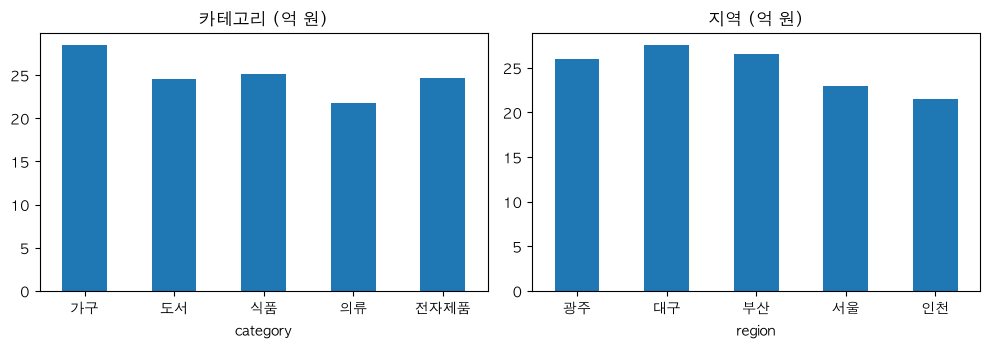

In [147]:
by_reg = df.groupby("region")["total_sales"].sum()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
(by_cat / 1e8).plot.bar(ax=ax[0], title="카테고리 (억 원)", rot=0)
(by_reg / 1e8).plot.bar(ax=ax[1], title="지역 (억 원)", rot=0)
plt.tight_layout()
plt.show()

In [148]:
pv = df.pivot_table(index="region", columns="category",
values="total_sales", aggfunc="sum")
(pv / 1e8).round(1)

category,가구,도서,식품,의류,전자제품
region,,,,,
광주,5.1,3.4,5.0,5.4,7.1
대구,7.2,5.0,5.8,4.8,4.7
부산,6.6,5.4,6.8,3.6,4.1
서울,4.4,6.3,3.8,4.2,4.3
인천,5.2,4.3,3.8,3.9,4.4


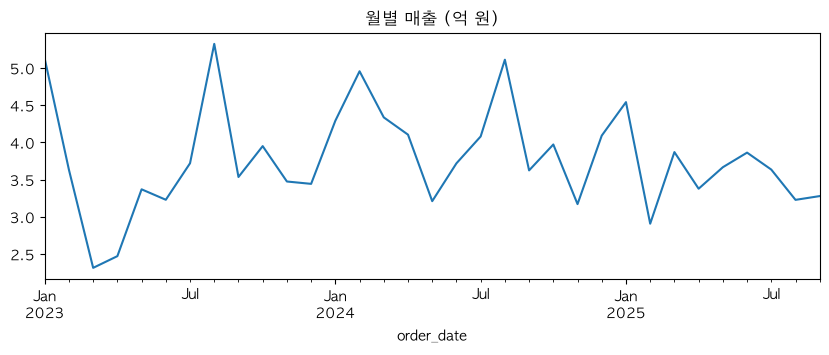

(Period('2023-08', 'M'), np.float64(5.3))

In [149]:
month = df["order_date"].dt.to_period("M")
monthly = df.groupby(month)["total_sales"].sum() / 1e8
monthly.plot(figsize=(10, 3.2), title="월별 매출 (억 원)")
plt.show()
monthly.idxmax(), round(monthly.max(), 1)

평균: 22.05 일
중앙값: 2.0 일
결측치 제외 데이터 개수: 852


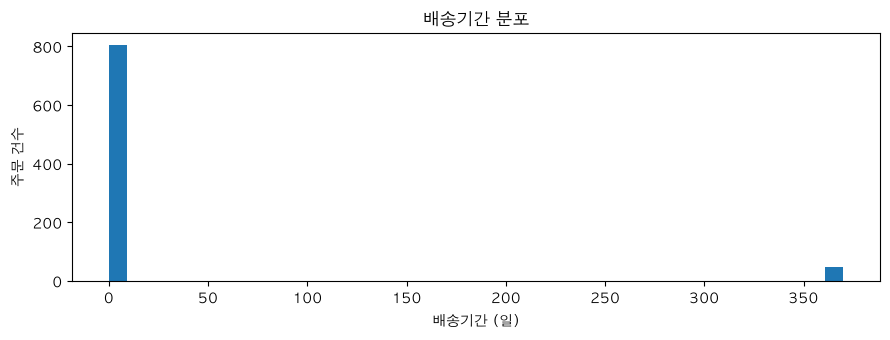

300일 초과: 47


11     365.0
20     369.0
29     365.0
41     368.0
68     364.0
99     367.0
110    365.0
131    369.0
165    368.0
192    367.0
199    364.0
215    368.0
326    367.0
334    368.0
338    367.0
361    367.0
383    370.0
397    366.0
412    368.0
425    370.0
527    365.0
542    365.0
543    365.0
546    367.0
585    364.0
592    368.0
608    365.0
633    370.0
638    365.0
685    366.0
694    369.0
747    364.0
750    367.0
775    366.0
784    368.0
786    364.0
810    365.0
813    367.0
828    366.0
853    367.0
884    366.0
887    369.0
888    365.0
895    364.0
936    368.0
939    369.0
982    366.0
dtype: float64

In [150]:

shipping = df.loc[~df["date_error"]]
days = (shipping["delivery_date"] - shipping["shipping_date"]).dt.days
days = days.dropna()

print("평균:", round(days.mean(), 2), "일")
print("중앙값:", round(days.median(), 2), "일")
print("결측치 제외 데이터 개수:",len(days))
days.plot.hist(bins=40, figsize=(9, 3.5), title="배송기간 분포")
plt.xlabel("배송기간 (일)")
plt.ylabel("주문 건수")
plt.tight_layout()
plt.show()

long_days = days[days > 300]
print("300일 초과:", len(long_days))
long_days

5) 날짜 역전과 결측을 제외한 852건의 평균은 22.05일, 중앙값은 2일이다. 오른쪽 끝의 364~370일짜리 47건이 평균을 끌어올려 둘의 차이가 크다.  
1년인 365일 주변에서만 해당 데이터가 나타나는 것으로 보아 연도 오기이고,
364일이 나오는 경우는 날짜역전으로 결측치 처리하고, 365~370 사이의 데이터는 365를 빼서 데이터로 사용해야한다.


satisfaction
1.0    0.08
2.0    0.12
3.0    0.08
4.0    0.09
5.0    0.07
Name: status, dtype: float64


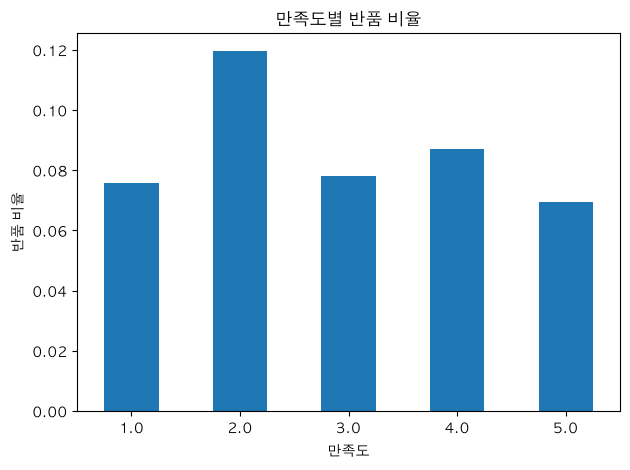

In [151]:
#6) 만족도가 낮을수록 반품이 많은가?

return_rate = (df["status"] == "반품").groupby(df["satisfaction"]).mean()

print(return_rate.round(2))

return_rate.plot.bar(title="만족도별 반품 비율", rot=0)
plt.xlabel("만족도")
plt.ylabel("반품 비율")
plt.tight_layout()
plt.show()

6) 아니다. 4점의 반품 비율이 1점, 3점보다 높기 때문에 만족도가 낮을수록 반품이 많다고 보기는 어렵다.

In [152]:
by_category = df.groupby("category").agg(
    주문건수=("total_sales", "size"),
    총매출=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean")
)

by_category.round(2)

,주문건수,총매출,평균단가,평균수량
category,,,,
가구,213,2.843337e+09,257322.91,51.04
도서,204,2.453240e+09,238500.64,49.50
식품,210,2.513274e+09,255232.93,47.31
의류,170,2.181904e+09,249447.16,51.61
전자제품,207,2.471628e+09,249651.61,47.96
